In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, cheby1, bilinear, lfilter, freqz

# Sampling rate exceeds twice the highest signal frequency.
fs = 20000
order = 4
ripple = 0.5  # Chebyshev Type I passband ripple in dB
t = np.arange(int(0.1 * fs)) / fs
tones = np.array([1000, 2000, 3000, 4000])
signals = np.sin(2 * np.pi * tones[:, None] * t)
x = signals.sum(axis=0)

# Prewarp cutoff in rad/s before the bilinear transform.
def design_filter(kind, cutoff):
    omega = 2 * fs * np.tan(np.pi * cutoff / fs)
    if kind == 'butter':
        b, a = butter(order, omega, analog=True)
    else:
        b, a = cheby1(order, ripple, omega, analog=True)
    return bilinear(b, a, fs=fs)

# Apply each filter independently to the combined input.
bb, ab = design_filter('butter', 2000)
bc, ac = design_filter('cheby', 3000)
yb = lfilter(bb, ab, x)
yc = lfilter(bc, ac, x)

# Omit the first 20 ms from FFTs to exclude startup transients.
# The remaining 80 ms contains an integer number of tone cycles.
start = int(0.02 * fs)
def spectrum(y):
    segment = y[start:]
    f = np.fft.rfftfreq(len(segment), d=1 / fs)
    amplitude = np.abs(np.fft.rfft(segment)) / len(segment)
    amplitude[1:-1] *= 2
    return f, amplitude

def plot_domains(y, title, cutoff=None):
    fig, ax = plt.subplots(2, 1, figsize=(10, 6))
    show = (t >= 0.02) & (t < 0.023)
    ax[0].stem(1000 * (t[show] - 0.02), y[show],
               basefmt=' ', markerfmt='o', linefmt='C0-')
    ax[0].set(title=title + ' - time domain',
              xlabel='Time from 20 ms (ms)', ylabel='Amplitude')
    f, amplitude = spectrum(y)
    ax[1].plot(f / 1000, amplitude)
    ax[1].set(title=title + ' - frequency domain',
              xlabel='Frequency (kHz)', ylabel='Amplitude',
              xlim=(0, 5), ylim=(0, 1.12))
    if cutoff is not None:
        ax[1].axvline(cutoff / 1000, color='C3',
                      linestyle='--', label='Cutoff')
        ax[1].legend()
    for axis in ax:
        axis.grid(True, alpha=0.35)
    fig.tight_layout()
    plt.show()

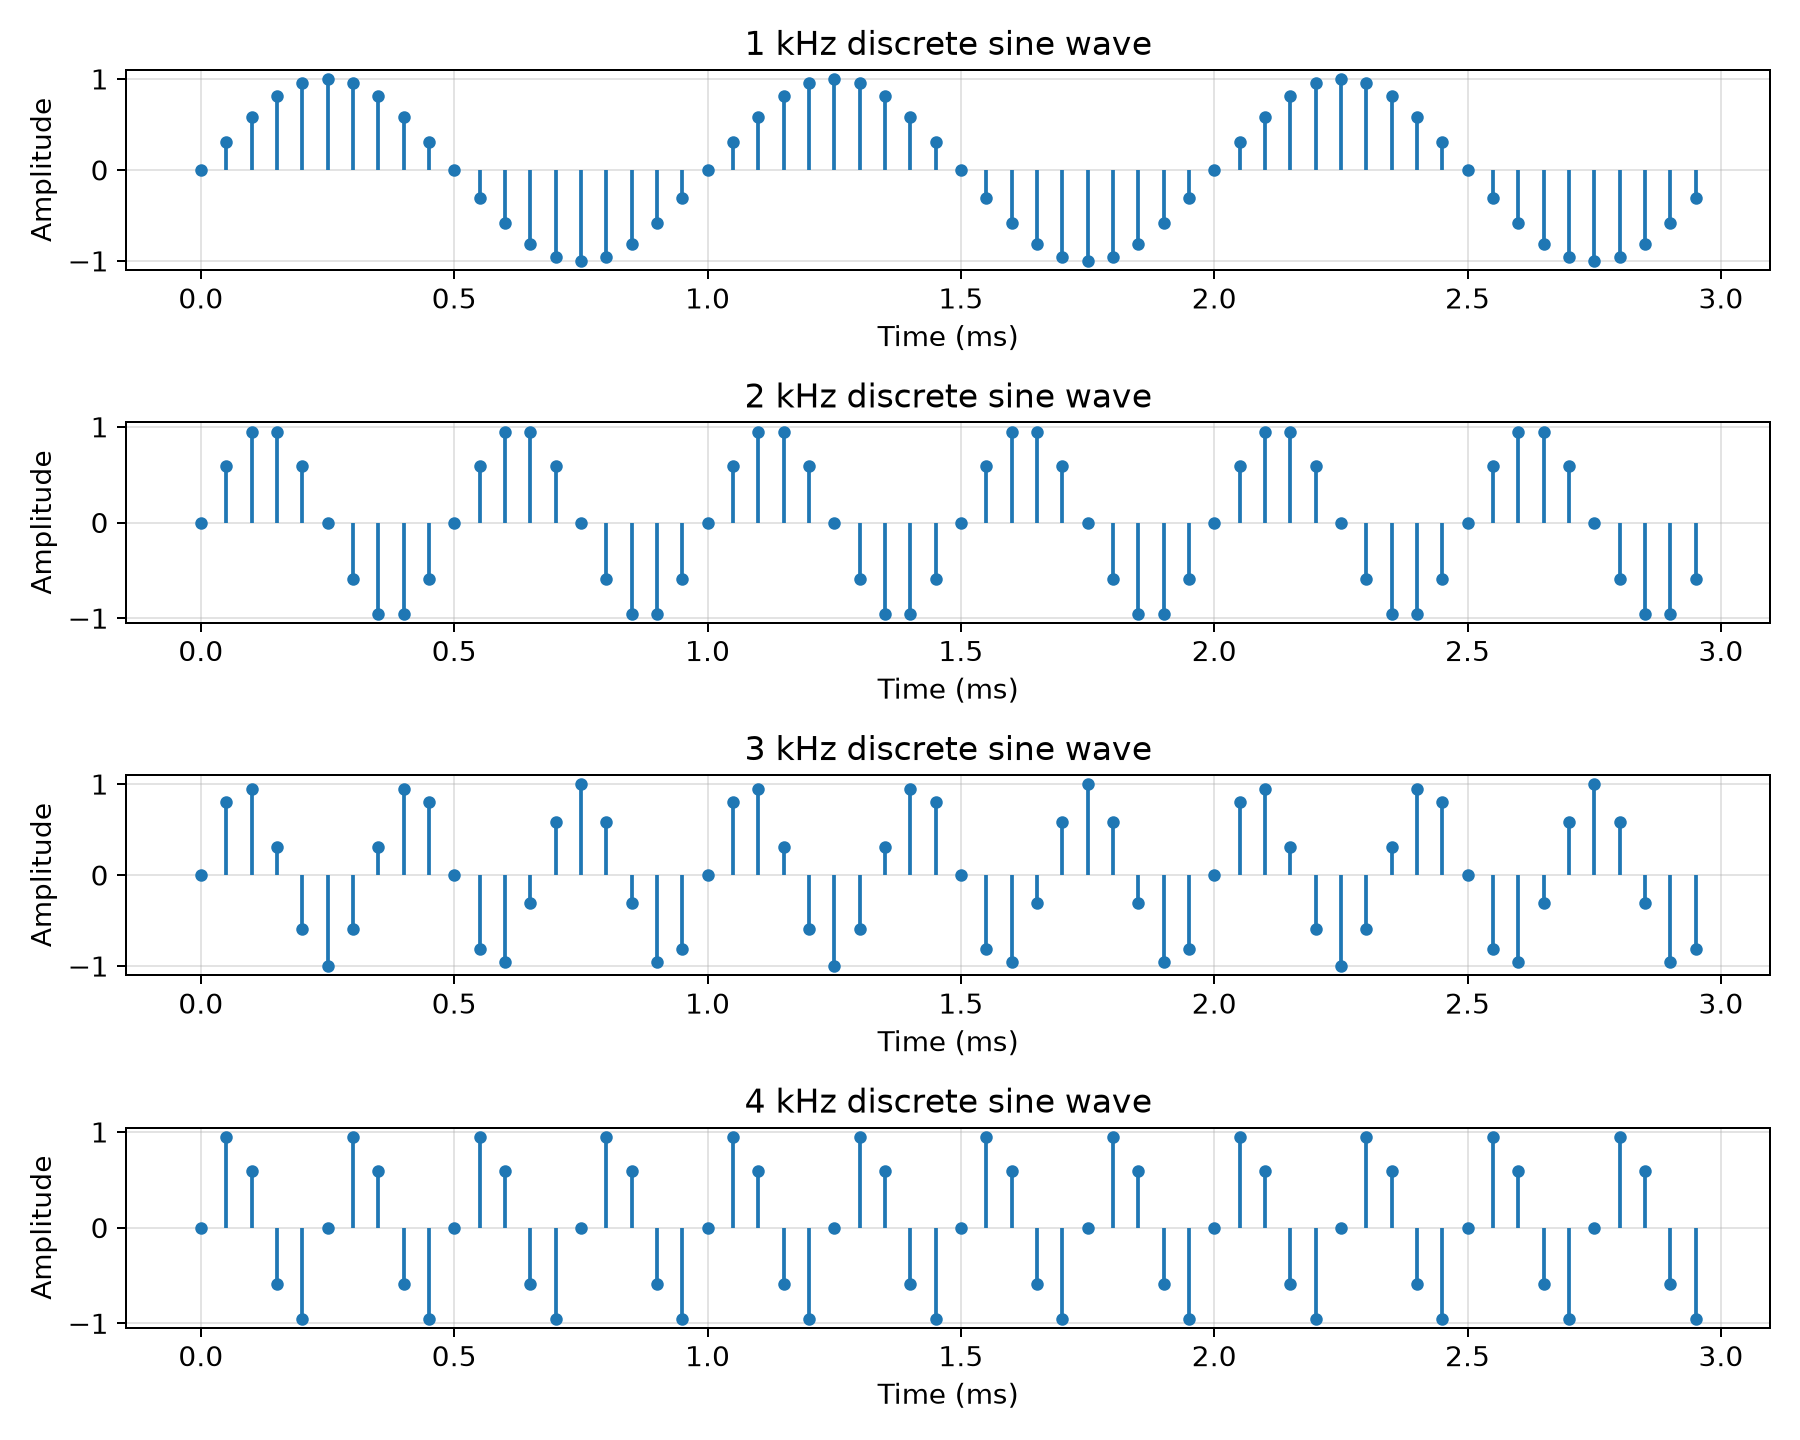

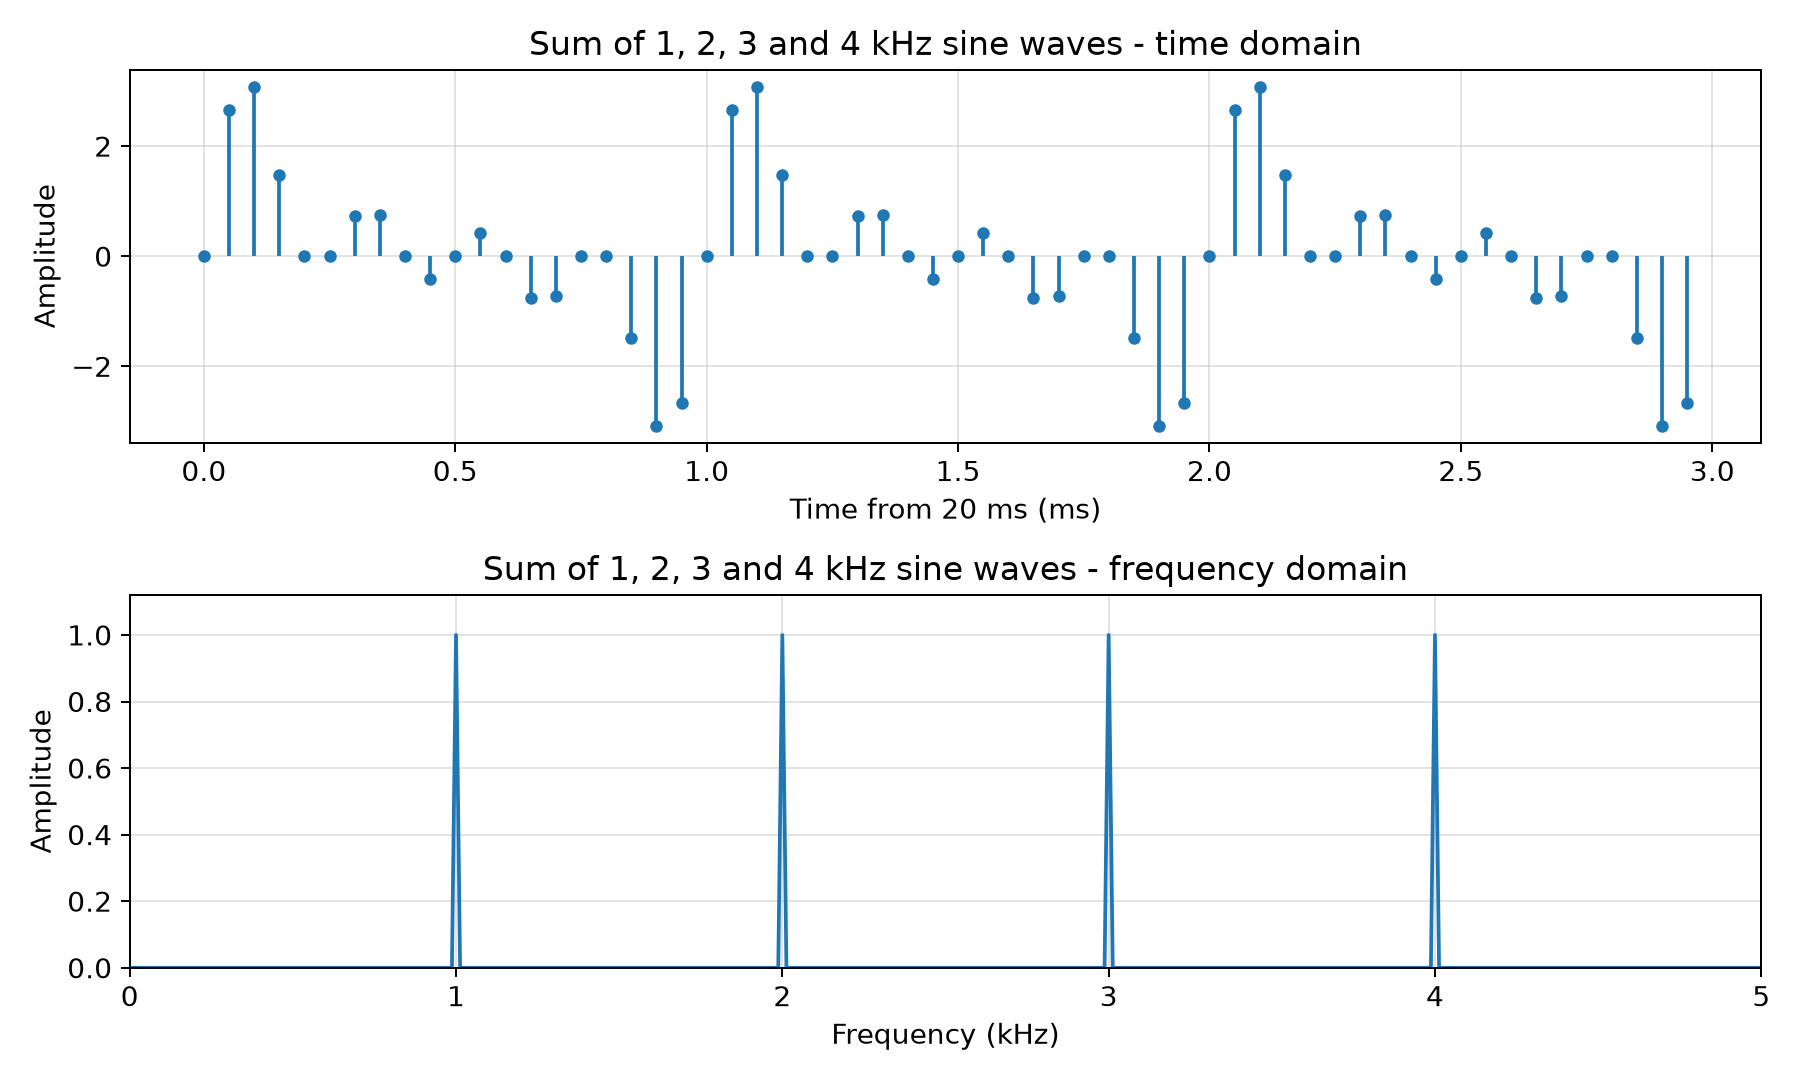

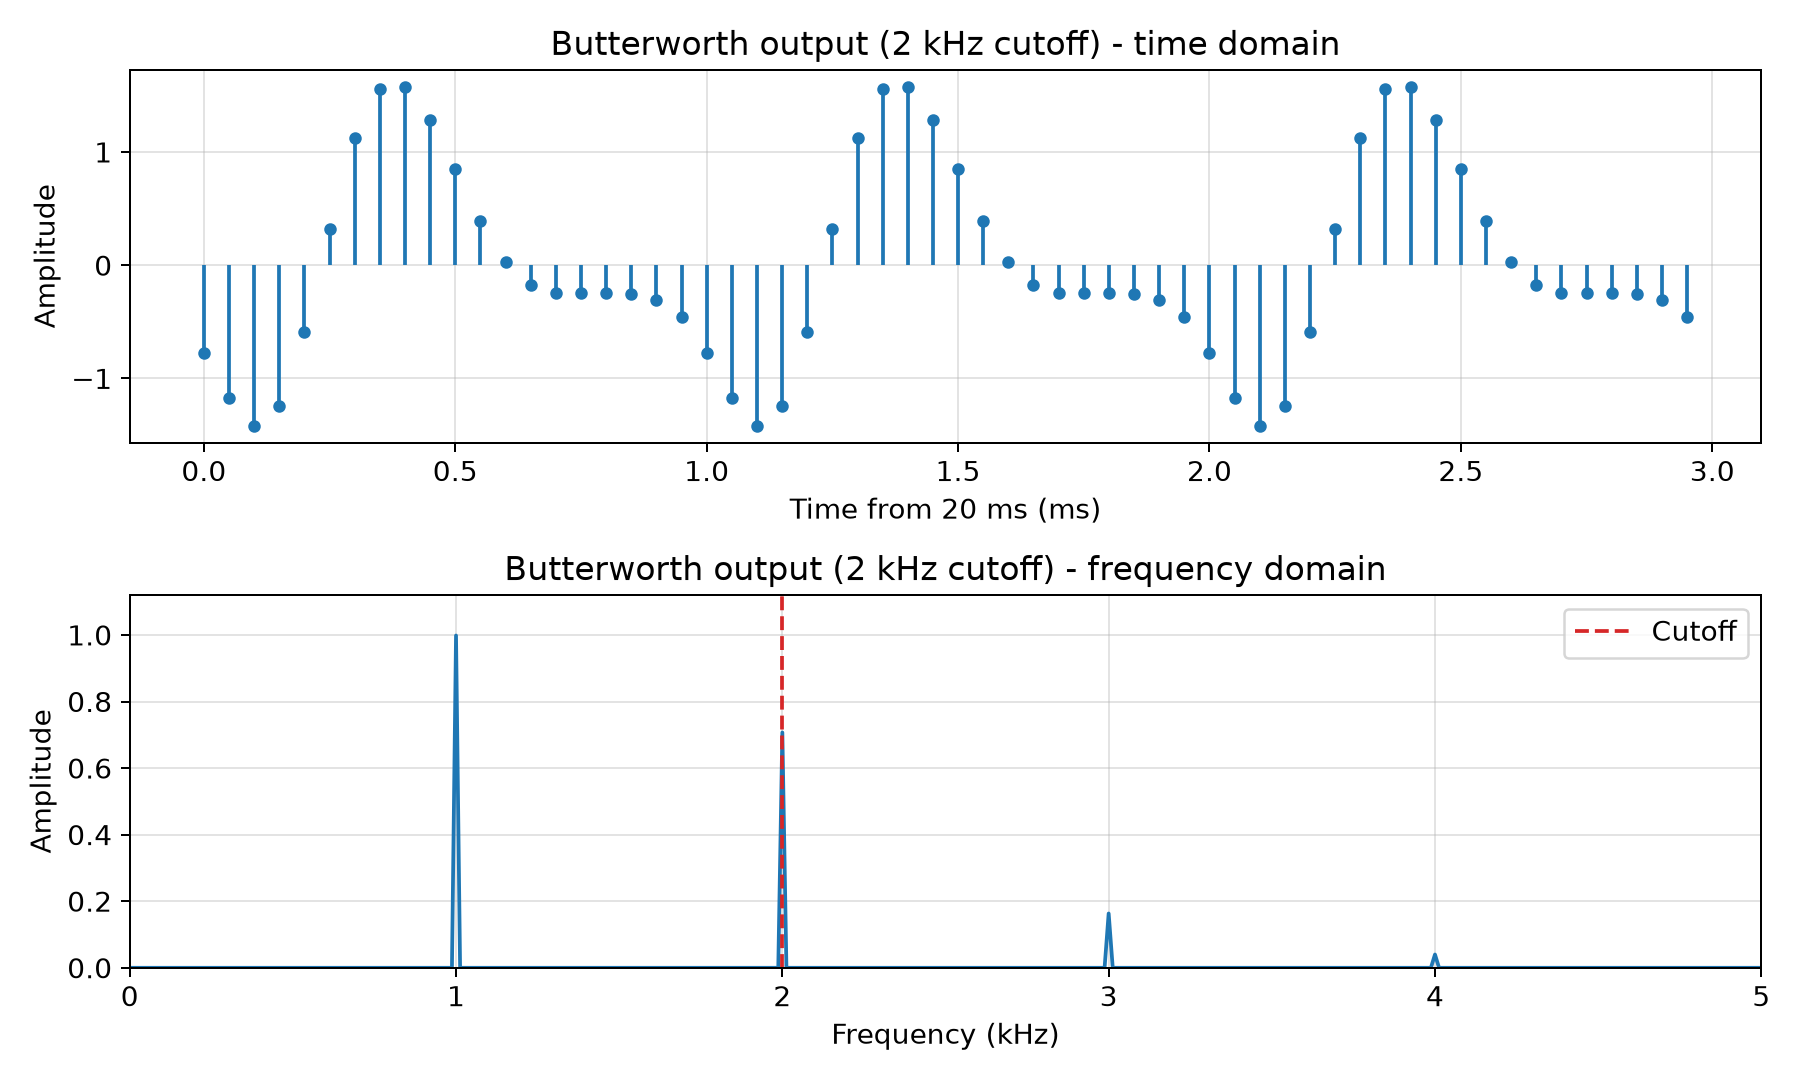

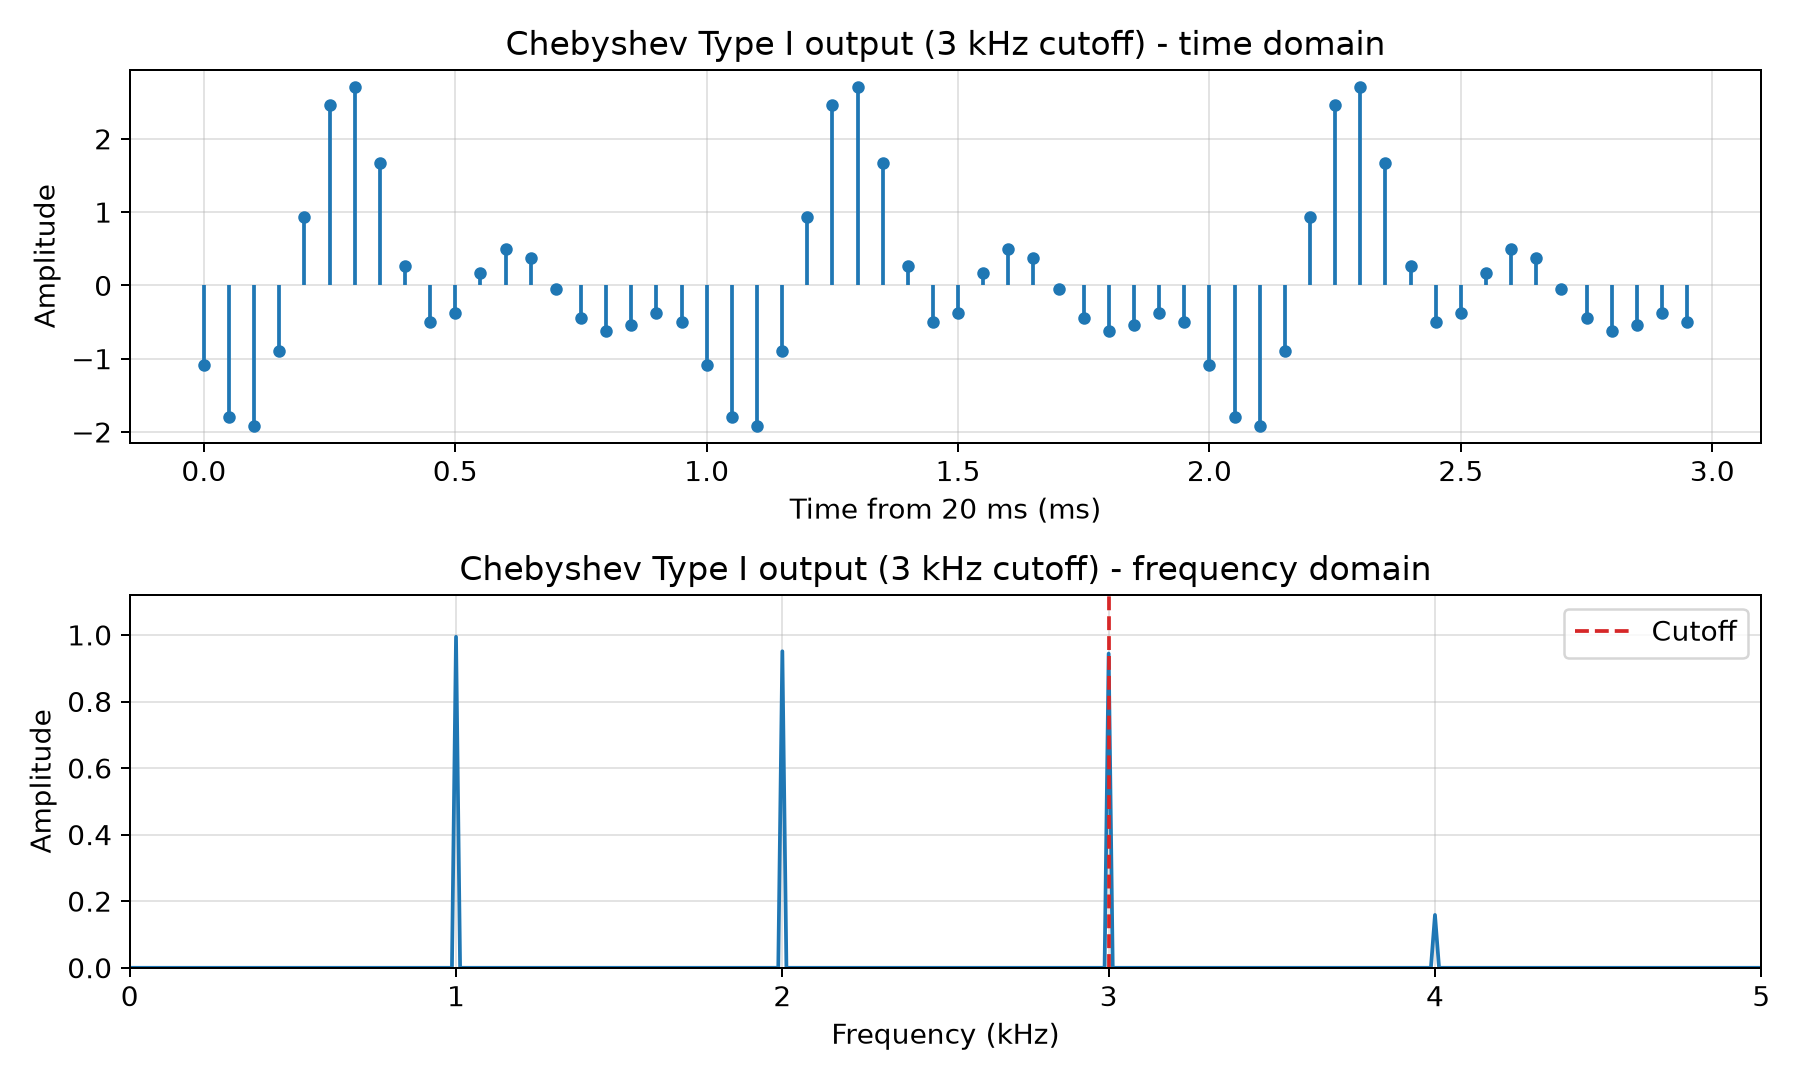

In [2]:
# Plot the four discrete sine waves.
fig, axes = plt.subplots(4, 1, figsize=(10, 8))
show = t < 0.003
for axis, signal, tone in zip(axes, signals, tones):
    axis.stem(1000 * t[show], signal[show], basefmt=' ')
    axis.set(title=f'{tone / 1000:g} kHz discrete sine wave',
             xlabel='Time (ms)', ylabel='Amplitude')
    axis.grid(True, alpha=0.35)
fig.tight_layout()
plt.show()

plot_domains(x, 'Sum of 1, 2, 3 and 4 kHz sine waves')
plot_domains(yb, 'Butterworth output (2 kHz cutoff)', 2000)
plot_domains(yc, 'Chebyshev Type I output (3 kHz cutoff)', 3000)

In [3]:
# Check measured spectral amplitudes against filter gains.
print('Frequency  Input  Butterworth  Chebyshev I')
for tone in tones:
    values = []
    for y in (x, yb, yc):
        f, amplitude = spectrum(y)
        values.append(amplitude[np.argmin(np.abs(f - tone))])
    print(f'{tone:4d} Hz    {values[0]:.4f}   '
          f'{values[1]:.4f}       {values[2]:.4f}')

np.savetxt('filter_coefficients.txt',
           np.vstack((bb, ab, bc, ac)), fmt='%.12g',
           header='Rows: Butterworth b, a; Chebyshev Type I b, a')

Frequency  Input  Butterworth  Chebyshev I
1000 Hz    1.0000   0.9984       0.9945
2000 Hz    1.0000   0.7071       0.9510
3000 Hz    1.0000   0.1631       0.9441
4000 Hz    1.0000   0.0400       0.1587
